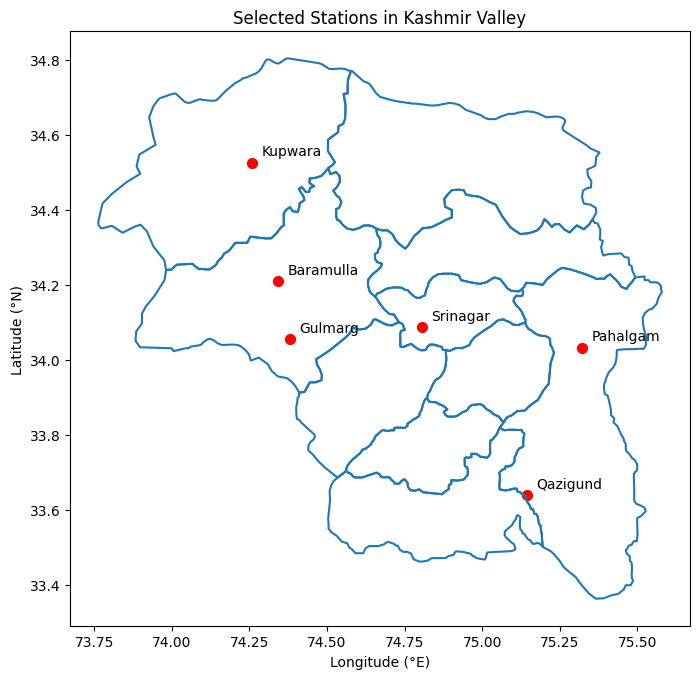

In [11]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

adm2 = gpd.read_file("gadm41_IND_shp/gadm41_IND_2.shp")

valley_districts = ["Anantnag", "Badgam", "Bandipore", "Baramulla",
    "Ganderbal", "Kulgam", "Kupwara", "Pulwama","Shupiyan", "Srinagar"]

valley = adm2[(adm2["GID_1"] == "Z01.14_1") &(adm2["NAME_2"].isin(valley_districts))]

stations = pd.DataFrame({"Station": ["Srinagar", "Gulmarg", "Pahalgam","Baramulla", "Kupwara", "Qazigund"],

    "Latitude": [34.085652, 34.053633, 34.0322,34.2087, 34.52484, 33.63828],

    "Longitude": [74.805553, 74.381880, 75.3226, 74.3435, 74.25953, 75.14261]})

points = gpd.GeoDataFrame(stations, geometry=gpd.points_from_xy(stations["Longitude"], 
                                                                stations["Latitude"]), crs="EPSG:4326")
fig, ax = plt.subplots(figsize=(8, 8))

valley.boundary.plot(ax=ax)

points.plot(ax=ax, color="red", markersize=50)

for i, row in stations.iterrows():
    ax.text(row["Longitude"] + 0.03, row["Latitude"] + 0.02, row["Station"], fontsize=10)

ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title("Selected Stations in Kashmir Valley")

plt.show()